# **Netflix Churn Analysis**

**Team:** Netflix Watchers  
**Authors:** Mahek Kothari (@mahekkothari), Kirsten Perez (@kirstenperez)  
**Created:** October 21, 2026  
**Last Modified:** November 14, 2026  

## Problem Statement
Which subscribers are most likely to cancel their Netflix subscription and what behavioral or account-level factors best explain why? Can these risk factors be made into retention strategies?  

## Dataset
- **Source:** [Netflix Customer Churn & Engagement Analytics](https://www.kaggle.com/datasets/zeyadmohamed26/netflix-customer-churn-and-engagement-analytics) (Kaggle, CC0 license)  
- **Size:** 5,000 rows x 14 columns

## Notebook Table of Contents:

**0. Notebook Setup**
- 0.1 Load Libraries
- 0.2 Load the Dataset

**1. Inspecting the Data**
- 1.1 Data Overview
- 1.2 Descriptive Statistics

**2. Cleaning the Data**
- 2.1 Cleaning Decisions
- 2.2 Load into a SQL Database

**3. Exploratory Data Analysis**
- 3.1 Churned vs Stayed
- 3.2 Viewing Activity vs Churn
- 3.3 Churn by Account Factors
- 3.4 Churn by Demographics & Genre
- 3.5 Correlation Check

**4. Conclusions**

**5. Classification Model**
- 5.1 Prepare the Features
- 5.2 Split into Train and Test Sets
- 5.3 Train the Baseline Model (Logistic Regression)
- 5.4 Evaluate the Model

## **0. Notebook Setup**

### 0.1 Load Libraries

In [1]:
# Import libraries
import pandas as pd
import sqlite3
import os
import kagglehub
import matplotlib.pyplot as plt
%matplotlib inline

# Modeling libraries
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay)

/Users/mahekkothari/netflix-churn-analysis/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/mahekkothari/netflix-churn-analysis/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 0.2 Load the Dataset

In [2]:
# Download the latest version of the dataset from Kaggle
path = kagglehub.dataset_download("zeyadmohamed26/netflix-customer-churn-and-engagement-analytics")

print("Path to dataset files:", path)

Path to dataset files: /Users/mahekkothari/.cache/kagglehub/datasets/zeyadmohamed26/netflix-customer-churn-and-engagement-analytics/versions/1


In [3]:
# Load the CSV into a DataFrame
df = pd.read_csv(os.path.join(path, "netflix_customer_churn.csv"))

# Show top 5 rows
df.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


## **1. Inspecting the Data**

### 1.1 Data Overview

Before analyzing the dataset, we wanted to make sure everything matched what the Kaggle page described (5,000 rows, 14 columns, and no missing values). We also checked that each column has the right data type, that every `customer_id` is unique (so no subscriber shows up twice), and that there are no missing values or duplicate rows. These checks help us decide whether the data needs any cleaning.

In [4]:
# Print the dataset size and column info
print("=== Dataset Size ===")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\n=== Column Info ===")
df.info()

# Verify customer_id is unique (one row per subscriber)
print("\n=== Unique ID Check ===")
print("Unique IDs:", df["customer_id"].nunique())
print("Total rows:", len(df))
print("customer_id is unique:", df["customer_id"].is_unique)

# Verify prices match with plans
print("\n=== Plan Check ===")
display(pd.crosstab(df["subscription_type"], df["monthly_fee"]))

=== Dataset Size ===
Rows: 5000
Columns: 14

=== Column Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   object 
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   object 
 3   subscription_type       5000 non-null   object 
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   object 
 7   device                  5000 non-null   object 
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   object 
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000

monthly_fee,8.99,13.99,17.99
subscription_type,,,
Basic,1661,0,0
Premium,0,0,1693
Standard,0,1646,0


In [5]:
# Count missing values for each column
print("=== Missing Values ===")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

# Count duplicate rows (dropping customer_id since it's unique)
print("\n=== Duplicate Rows ===")
print("Duplicate rows:", df.drop(columns="customer_id").duplicated().sum())

=== Missing Values ===
customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64

Total missing values: 0

=== Duplicate Rows ===
Duplicate rows: 0


**Observations:**

- The dataset matches the Kaggle description: 5,000 rows, 14 columns, and no missing values
- `customer_id` is unique and there are no duplicate rows, so no subscriber appears twice
- Each plan has exactly one price, so `monthly_fee` gives the same information as `subscription_type`:
  - Basic → 8.99 dollars
  - Standard → 13.99 dollars
  - Premium → 17.99 dollars
- All data types are correct, so no conversion is needed

### 1.2 Descriptive Statistics

In [6]:
# Show the counts for each categorical column
for col in ["gender", "subscription_type", "region", "device", "payment_method", "favorite_genre"]:
    print("---", col, "---")
    print(df[col].value_counts().to_string())
    print("Average per category:", round(df[col].value_counts().mean()))
    print()
 
# Show the summary statistics for the numeric columns
df.describe()

--- gender ---
gender
Female    1711
Male      1654
Other     1635
Average per category: 1667

--- subscription_type ---
subscription_type
Premium     1693
Basic       1661
Standard    1646
Average per category: 1667

--- region ---
region
South America    873
Europe           867
North America    851
Asia             841
Africa           803
Oceania          765
Average per category: 833

--- device ---
device
Tablet     1048
Laptop     1006
Mobile     1004
TV          993
Desktop     949
Average per category: 1000

--- payment_method ---
payment_method
Debit Card     1030
PayPal         1026
Crypto          995
Gift Card       976
Credit Card     973
Average per category: 1000

--- favorite_genre ---
favorite_genre
Drama          731
Documentary    729
Romance        725
Sci-Fi         720
Horror         713
Action         697
Comedy         685
Average per category: 714



,age,watch_hours,last_login_days,monthly_fee,churned,number_of_profiles,avg_watch_time_per_day
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,43.847400,11.649450,30.089800,13.683400,0.503000,3.024400,0.874800
std,15.501128,12.014654,17.536078,3.692062,0.500041,1.415841,2.619824
min,18.000000,0.010000,0.000000,8.990000,0.000000,1.000000,0.000000
25%,30.000000,3.337500,15.000000,8.990000,0.000000,2.000000,0.110000
50%,44.000000,8.000000,30.000000,13.990000,1.000000,3.000000,0.290000
75%,58.000000,16.030000,45.000000,17.990000,1.000000,4.000000,0.720000
max,70.000000,110.400000,60.000000,17.990000,1.000000,5.000000,98.420000


**Observations:** Every category has almost the same number of subscribers, which isn't realistic, but it makes sense since the dataset is synthetic. This is a limitation of our analysis since real Netflix data might look different

**Categorical columns**
- `gender`: There are 3 options with an average of 1,667 subscribers each. Female has the most with 1,711 and Other has the least with 1,635
- `subscription_type`: There are 3 plans with an average of 1,667 subscribers each. Premium has the most with 1,693 and Standard has the least with 1,646
- `region`: There are 6 regions with an average of 833 subscribers each. South America has the most with 873 and Oceania has the least with 765
- `device`: There are 5 devices with an average of 1,000 subscribers each. Tablet has the most with 1,048 and Desktop has the least with 949
- `payment_method`: There are 5 payment methods with an average of 1,000 subscribers each. Debit Card has the most with 1,030 and Credit Card has the least with 973
- `favorite_genre`: There are 7 genres with an average of 714 subscribers each. Drama has the most with 731 and Comedy has the least with 685

**Numeric columns**
- `age`: Ages range from 18-70 and are spread out evenly with the mean and median about the same (around 44)
- `watch_hours`: The mean (11.65) is higher than the median (8.0) because a small group of heavy watchers (up to 110.4 hours) pulls the average up. Most subscribers watch much less than the mean suggests
- `last_login_days`: Days since last login range from 0 to 60 and are spread out evenly with the mean and median about the same (around 30)
- `monthly_fee`: There are only 3 options (8.99 dollars, 13.99 dollars, and 17.99 dollars) with 1 for each plan, so this column gives the same information as `subscription_type`
- `churned`: There are only 2 options (0 = stayed and 1 = cancelled). The mean is 0.50, so about half of subscribers cancelled and there are enough of both groups to compare fairly
- `number_of_profiles`: There are only 5 options (1, 2, 3, 4, and 5) since an account can have up to 5 profiles
- `avg_watch_time_per_day`: The max is 98.42 hours a day, which is impossible since a day only has 24 hours. The Kaggle page says the range should be 0.01 to 4.97, so this column will be removed during cleaning

## **2. Cleaning the Data**  

### 2.1 Cleaning Decisions

1. **No rows dropped:** There are no missing values or duplicate rows, so nothing needs to be removed
2. **Dropped `monthly_fee`:** As observed in 1.1 Data Overview, each plan has exactly one price, so this column gives the same information as `subscription_type`
3. **Dropped `avg_watch_time_per_day`:** As observed in 1.2 Descriptive Statistics, the max is 98.42 hours a day, which is impossible since a day only has 24 hours. This means the data in this column might not be valid, so `watch_hours` is used for viewing activity instead
4. **Added `age_group`:** Ages are grouped into life stages so churn can be compared across age groups:
   - Young Adult (18–24)
   - Adult (25–44)
   - Middle-Aged (45–64)
   - Senior (65–70)
5. **Saved cleaned data:** The cleaned dataset is saved as `netflix_churn_clean.csv` in the `data` folder so it can be used outside this notebook

In [7]:
# Make a cleaned copy
df_clean = df.copy()

# Drop avg_watch_time_per_day and monthly_fee columns
df_clean = df_clean.drop(columns=["avg_watch_time_per_day", "monthly_fee"])

# Group ages into groups
df_clean["age_group"] = pd.cut(df_clean["age"], bins=[17, 24, 44, 64, 70],
                               labels=["Young Adult", "Adult", "Middle-Aged", "Senior"])

# Verify no rows were lost, 13 columns (2 cols dropped and 1 added), and every age was grouped in a group
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("\nColumns:", list(df_clean.columns))
print("\nAges without a group:", df_clean["age_group"].isnull().sum())
print(df_clean["age_group"].value_counts().sort_index())

Original shape: (5000, 14)
Cleaned shape: (5000, 13)

Columns: ['customer_id', 'age', 'gender', 'subscription_type', 'watch_hours', 'last_login_days', 'region', 'device', 'churned', 'payment_method', 'number_of_profiles', 'favorite_genre', 'age_group']

Ages without a group: 0
age_group
Young Adult     707
Adult          1847
Middle-Aged    1884
Senior          562
Name: count, dtype: int64


In [8]:
# Save the cleaned data as a CSV file in the data folder
os.makedirs("../data", exist_ok=True)
df_clean.to_csv("../data/netflix_churn_clean.csv", index=False)

# Verify the file was saved and has the same shape as df_clean
saved = pd.read_csv("../data/netflix_churn_clean.csv")
print("Saved file shape:", saved.shape)

Saved file shape: (5000, 13)


### 2.2 Load into a SQL Database  

The cleaned data is loaded into a SQLite database so churn rates can be calculated with SQL `GROUP BY` queries.  

In [9]:
# Load the cleaned data into an in-memory SQLite table called "subscribers"
conn = sqlite3.connect(":memory:")
df_clean.to_sql("subscribers", conn, index=False, if_exists="replace")

# Verify the table has the same number of rows as df_clean
query = """
SELECT COUNT(*) AS n_rows
FROM subscribers;
"""
pd.read_sql_query(query, conn)

,n_rows
0,5000


## **3. Exploratory Data Analysis**

In this section, we compare subscribers who churned with subscribers who stayed to find which factors are linked to cancelling. We use SQL `GROUP BY` queries to calculate averages and churn rates for each group, then plot the results as bar charts so the differences are easy to see.

### 3.1 Churned vs Stayed

We counted how many subscribers churned and how many stayed. This shows whether the two groups are similar in size, which matters because the rest of this section compares them.

Stayed     2485
Churned    2515
Name: count, dtype: int64


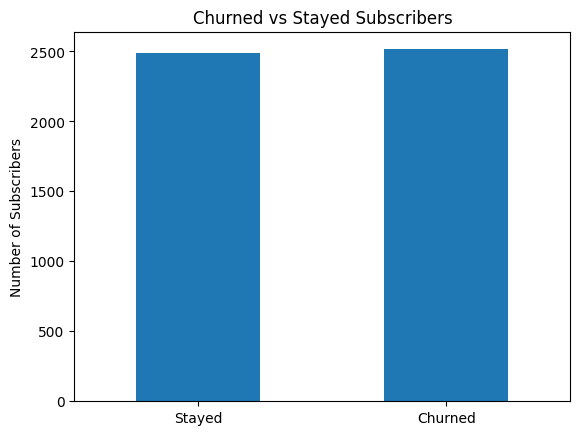

In [10]:
# Count the number of churned vs stayed subscribers
churn_counts = df_clean["churned"].value_counts().sort_index()

# Rename 0 and 1 to Stayed and Churned
churn_counts.index = ["Stayed", "Churned"]
print(churn_counts)

# Plot the number of churned vs stayed subscribers
churn_counts.plot(kind="bar")
plt.title("Churned vs Stayed Subscribers")
plt.xlabel("")
plt.ylabel("Number of Subscribers")
plt.xticks(rotation=0)
plt.show()

**Observations:** 2,515 subscribers churned and 2,485 stayed, so the two groups are almost the same size (about 50/50). This means comparisons between them are fair, since neither group is much smaller than the other.

### 3.2 Viewing Activity vs Churn

We compared watch hours and days since last login for subscribers who churned and those who stayed. These show how actively someone uses Netflix, so comparing them can reveal whether viewing activity is linked to cancelling. This can help retention teams decide which subscribers to focus on.

,status,subscribers,avg_watch_hours,avg_last_login_days
0,Stayed,2485,17.45,21.77
1,Churned,2515,5.92,38.31


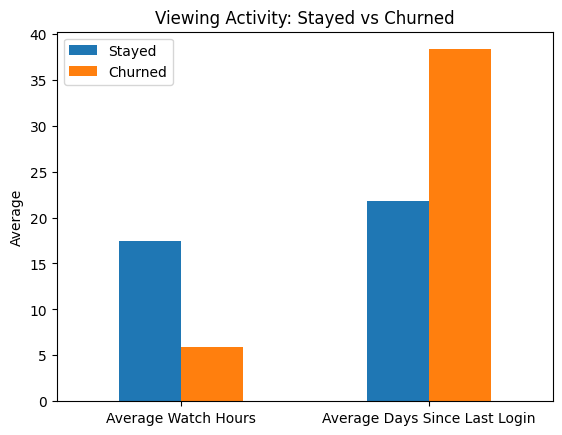

In [11]:
# Calculate the number of subscribers, average watch hours, and average days since last login for churned vs stayed
query = """
SELECT
    CASE churned WHEN 0 THEN 'Stayed' ELSE 'Churned' END AS status,
    COUNT(*) AS subscribers,
    ROUND(AVG(watch_hours), 2) AS avg_watch_hours,
    ROUND(AVG(last_login_days), 2) AS avg_last_login_days
FROM subscribers
GROUP BY churned
ORDER BY churned;
"""
activity = pd.read_sql_query(query, conn)

# Show the results table
display(activity)

# Plot both averages side by side, with one bar for Stayed and one for Churned
chart_data = activity.set_index("status")[["avg_watch_hours", "avg_last_login_days"]].T
chart_data.index = ["Average Watch Hours", "Average Days Since Last Login"]
chart_data.plot(kind="bar")
plt.title("Viewing Activity: Stayed vs Churned")
plt.xlabel("")
plt.ylabel("Average")
plt.xticks(rotation=0)
plt.legend(title="")
plt.show()

**Observations:**

- **Watch hours:** Subscribers who stayed watched an average of 17.45 hours compared to 5.92 hours for those who churned. Subscribers who stayed watched about 3x as much
- **Days since last login:** Subscribers who churned had gone an average of 38.31 days since their last login compared to 21.77 days for those who stayed. That's about 16.5 days longer without logging in

### 3.3 Churn by Account Factors

We compared the churn rate for each plan, payment method, device, region, and number of profiles. These describe how a subscriber's account is set up, so comparing them can reveal whether certain account setups are linked to cancelling. This can help retention teams decide which subscribers to focus on.

,subscription_type,subscribers,churned,churn_rate_pct
0,Basic,1661,1027,61.8
1,Standard,1646,748,45.4
2,Premium,1693,740,43.7


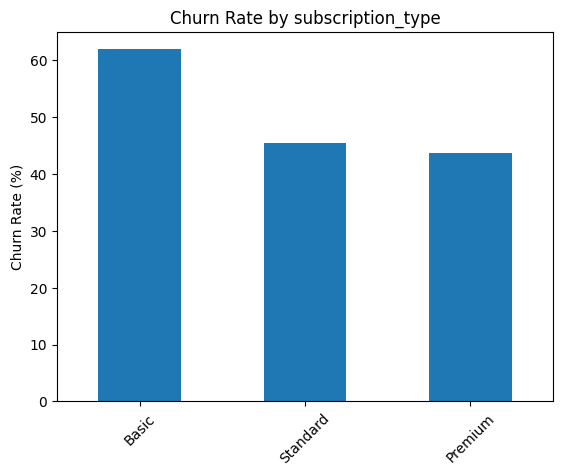

,payment_method,subscribers,churned,churn_rate_pct
0,Crypto,995,594,59.7
1,Gift Card,976,564,57.8
2,PayPal,1026,483,47.1
3,Debit Card,1030,450,43.7
4,Credit Card,973,424,43.6


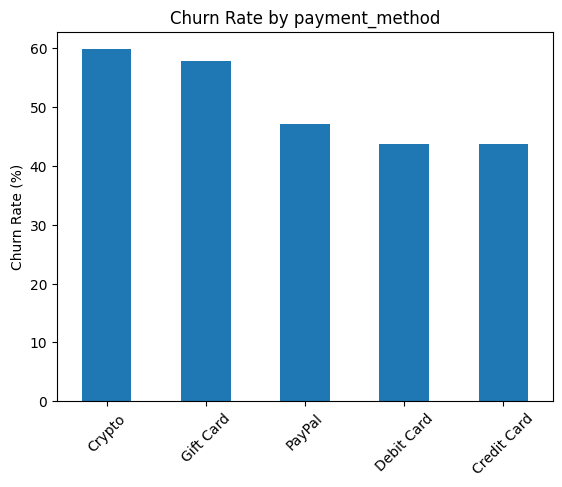

,device,subscribers,churned,churn_rate_pct
0,Laptop,1006,521,51.8
1,Mobile,1004,507,50.5
2,Tablet,1048,524,50.0
3,TV,993,496,49.9
4,Desktop,949,467,49.2


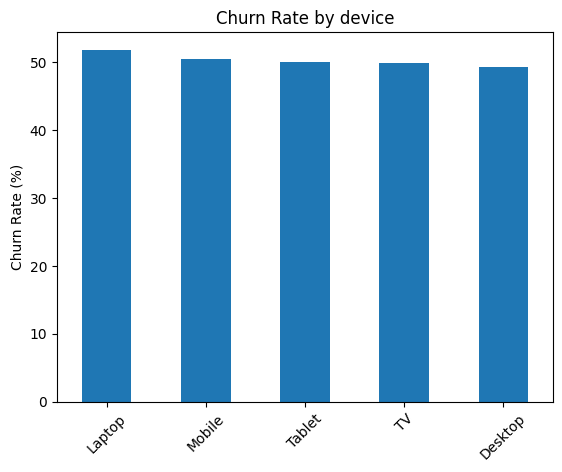

,region,subscribers,churned,churn_rate_pct
0,Europe,867,448,51.7
1,South America,873,449,51.4
2,Asia,841,426,50.7
3,Oceania,765,383,50.1
4,North America,851,421,49.5
5,Africa,803,388,48.3


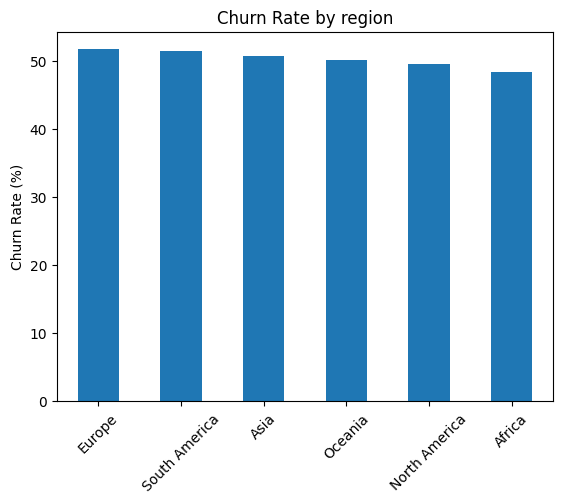

,number_of_profiles,subscribers,churned,churn_rate_pct
0,1,972,570,58.6
1,2,1001,575,57.4
2,3,994,575,57.8
3,4,999,375,37.5
4,5,1034,420,40.6


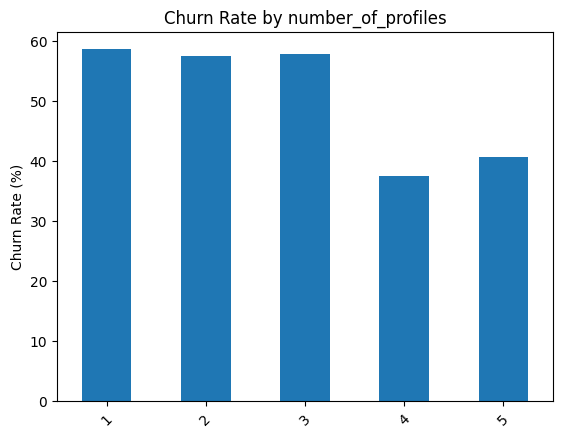

In [12]:
churn_by = {}

# Calculate the number of subscribers, number churned, and churn rate for each category
# sort number of profiles from 1 to 5 and everything else by highest churn rate
for col in ["subscription_type", "payment_method", "device", "region", "number_of_profiles"]:
    order = "number_of_profiles" if col == "number_of_profiles" else "churn_rate_pct DESC"
    query = f"""
    SELECT
        {col},
        COUNT(*) AS subscribers,
        SUM(churned) AS churned,
        ROUND(AVG(churned) * 100, 1) AS churn_rate_pct
    FROM subscribers
    GROUP BY {col}
    ORDER BY {order};
    """
    churn_by[col] = pd.read_sql_query(query, conn)

    # Show the results table
    display(churn_by[col])

    # Plot the churn rate for each category
    churn_by[col].plot(kind="bar", x=col, y="churn_rate_pct", legend=False)
    plt.title(f"Churn Rate by {col}")
    plt.xlabel("")
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=45)
    plt.show()

**Observations:**
- **Plan:** Basic has the highest churn rate at 61.8%, which is higher than the 45.4% for Standard and 43.7% for Premium
- **Payment method:** Crypto (59.7%) and Gift Card (57.8%) have much higher churn rates than PayPal (47.1%), Debit Card (43.7%), and Credit Card (43.6%). These two methods might churn more because they don't renew automatically the way cards and PayPal do
- **Device:** Churn rates range from 49.2% (Desktop) to 51.8% (Laptop). This is a small difference, so the device a subscriber uses doesn't seem to matter
- **Region:** Churn rates range from 48.3% (Africa) to 51.7% (Europe). This is a small difference, so region doesn't seem to matter either
- **Number of profiles:** Accounts with 1 to 3 profiles have churn rates around 57-59%, while accounts with 4 or 5 profiles drop to 37.5% and 40.6%. This is a large difference, so accounts shared by more people seem much less likely to cancel

### 3.4 Churn by Demographics & Genre

We compared the churn rate for each age group, gender, and favorite genre. These describe who the subscriber is and what they like to watch, so comparing them can reveal whether certain groups are linked to cancelling. This can help retention teams decide which subscribers to focus on.  

,age_group,subscribers,churned,churn_rate_pct
0,Young Adult,707,358,50.6
1,Adult,1847,913,49.4
2,Middle-Aged,1884,965,51.2
3,Senior,562,279,49.6


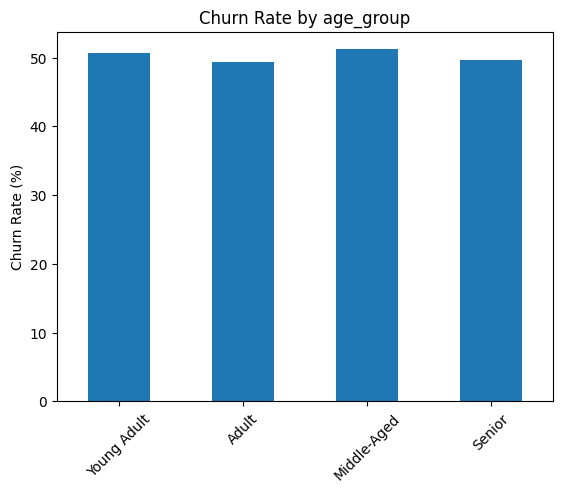

,gender,subscribers,churned,churn_rate_pct
0,Female,1711,874,51.1
1,Male,1654,827,50.0
2,Other,1635,814,49.8


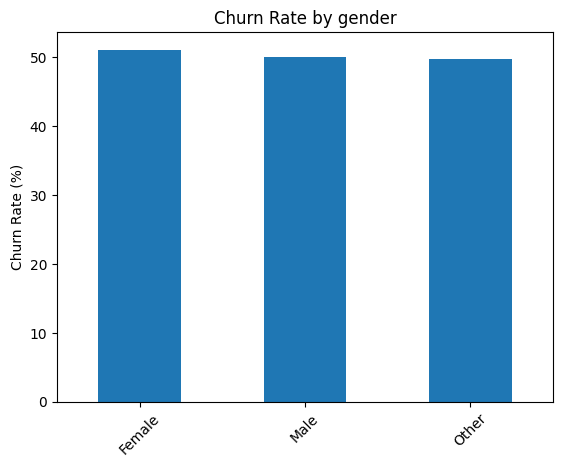

,favorite_genre,subscribers,churned,churn_rate_pct
0,Action,697,365,52.4
1,Drama,731,382,52.3
2,Horror,713,367,51.5
3,Documentary,729,370,50.8
4,Comedy,685,342,49.9
5,Romance,725,350,48.3
6,Sci-Fi,720,339,47.1


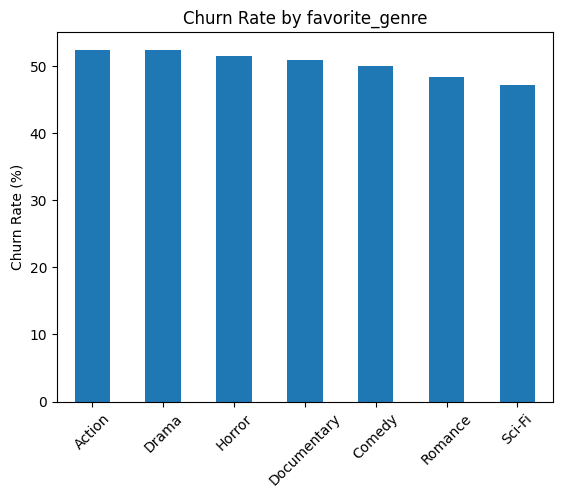

In [13]:
# Calculate the number of subscribers, number churned, and churn rate for each category
# sort age groups youngest to oldest and everything else by highest churn rate
for col in ["age_group", "gender", "favorite_genre"]:
    order = "MIN(age)" if col == "age_group" else "churn_rate_pct DESC"
    query = f"""
    SELECT
        {col},
        COUNT(*) AS subscribers,
        SUM(churned) AS churned,
        ROUND(AVG(churned) * 100, 1) AS churn_rate_pct
    FROM subscribers
    GROUP BY {col}
    ORDER BY {order};
    """
    churn_by[col] = pd.read_sql_query(query, conn)

    # Show the results table
    display(churn_by[col])

    # Plot the churn rate for each category
    churn_by[col].plot(kind="bar", x=col, y="churn_rate_pct", legend=False)
    plt.title(f"Churn Rate by {col}")
    plt.xlabel("")
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=45)
    plt.show()

**Observations:**

- **Age group:** Churn rates range from 49.4% (Adult) to 51.2% (Middle-Aged). This is an extremely small difference, so age doesn't seem to matter
- **Gender:** Churn rates range from 49.8% (Other) to 51.1% (Female). This is also a very small difference, so gender doesn't seem to matter either
- **Favorite genre:** Churn rates range from 47.1% (Sci-Fi) to 52.4% (Action). This is a larger but still small difference, so favorite genre doesn't seem to matter either

### 3.5 Correlation Check

We checked how strongly each numeric column is related to churn and to each other. Values range from -1 to 1, where values close to 0 mean no relationship and values closer to -1 or 1 mean a stronger relationship. Only numeric columns are included, since categorical columns were already compared using churn rates in 3.3 and 3.4.

In [14]:
# Calculate how strongly each numeric column is related to churn and to each other
numeric_cols = ["age", "watch_hours", "last_login_days", "number_of_profiles", "churned"]
df_clean[numeric_cols].corr().round(2)

,age,watch_hours,last_login_days,number_of_profiles,churned
age,1.00,0.03,0.02,0.02,-0.00
watch_hours,0.03,1.00,0.00,0.02,-0.48
last_login_days,0.02,0.00,1.00,0.02,0.47
number_of_profiles,0.02,0.02,0.02,1.00,-0.16
churned,-0.00,-0.48,0.47,-0.16,1.00


**Observations:**
- `watch_hours`: -0.48 with `churned`, which is a moderate negative relationship. Subscribers who watch more are less likely to churn
- `last_login_days`: 0.47 with `churned`, which is a moderate positive relationship. Subscribers who haven't logged in for longer are more likely to churn
- `number_of_profiles`: -0.16 with `churned`, which is a weak negative relationship. However, 3.3 shows a large drop in churn at 4 or more profiles. The correlation is low because the change is a sudden jump rather than a steady decline, and correlation only measures steady patterns
- `age`: 0.00 with `churned`, so age has no relationship with churn, which matches what we found in 3.4

None of the numeric columns are related to each other (all 0.03 or below), so each one gives separate information about the subscriber.

## **4. Conclusions**

Based on the comparisons in Section 3, the subscribers most likely to cancel are those with low viewing activity, 3 or fewer profiles, a Basic plan, or a crypto or gift card payment method. Device, region, age group, gender, and favorite genre made little difference, so retention efforts should focus on these four factors.

### Retention Strategies (in order of priority)

**1. Re-engage inactive subscribers**
Viewing activity was the clearest sign of churn, since subscribers who stayed watched about 3x as much as those who churned. Netflix could flag subscribers who haven't logged in for a few weeks and send them personalized recommendations, new release alerts, or "continue watching" reminders to bring them back before they cancel.

**2. Encourage more profiles on smaller accounts**
Accounts with 1 to 3 profiles were about 1.5x as likely to churn as accounts with 4 or 5 profiles. Netflix could prompt smaller accounts to add profiles for family members, since an account shared by more people may feel more valuable and be harder to cancel.

**3. Encourage Basic subscribers to upgrade**
Basic subscribers were about 1.4x as likely to churn as Premium subscribers. Netflix could offer them a limited-time discount or free trial of Standard or Premium so they can see the extra value, which may make them more likely to stay.

**4. Move crypto and gift card subscribers to automatic payments**
Crypto and gift card subscribers were about 1.3x as likely to churn as credit card subscribers. Netflix could send a reminder before their balance runs out and offer a small incentive, like a free month, for switching to automatic payments.

### Limitations
- The dataset is synthetic, so these patterns may not match real Netflix subscribers.
- These comparisons show which groups churn more, not why. Testing these strategies on real subscribers would show whether they actually reduce churn.

## **5. Classification Model**

In this section, we train a model that predicts whether a subscriber will churn. Our baseline model is the Logistic Regression then we will use other models to compare.

### 5.1 Prepare the Features

The model uses every column from `df_clean` except:
- `churned`, since that is what the model is predicting (the target)
- `customer_id`, since it is a random ID and doesn't say anything about the subscriber
- `age_group`, since it gives the same information as `age`

How we prepared the columns: 
- **Categorical columns** (plan, payment method, device, region, gender, favorite genre) are **one-hot encoded**, which turns each category into its own 0/1 column. The first category of each column (alphabetically) is dropped.
- **Numeric columns** (age, watch hours, days since last login, number of profiles) are **scaled** so they are all on the same scale.

In [15]:
# Choose which columns the model uses
numeric_features = ["age", "watch_hours", "last_login_days", "number_of_profiles"]
categorical_features = ["subscription_type", "payment_method", "device", "region", "gender", "favorite_genre"]

X = df_clean[numeric_features + categorical_features]  # features
y = df_clean["churned"]                                # 0 = stayed, 1 = churned

# Scale the numeric columns and one-hot encode the categorical columns
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(drop="first"), categorical_features),
])

print("Features:", X.shape[1], "columns")
print("Target counts:")
print(y.value_counts().sort_index())

Features: 10 columns
Target counts:
churned
0    2485
1    2515
Name: count, dtype: int64


### 5.2 Split into Train and Test Sets

The data is split into a **training set (80%)** that the model learns from and a **test set (20%)** that the model never sees during training. Scoring the model on the test set shows how well it would do on new subscribers. The split is **stratified**, so both sets have the same churn rate as the full dataset, and `random_state=42` makes the split the same every time the notebook is run.

In [16]:
# Split into 80% training data and 20% test data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Training set:", X_train.shape[0], "subscribers")
print("Test set:", X_test.shape[0], "subscribers")
print("\nChurn rate in training set:", round(y_train.mean() * 100, 1), "%")
print("Churn rate in test set:", round(y_test.mean() * 100, 1), "%")

Training set: 4000 subscribers
Test set: 1000 subscribers

Churn rate in training set: 50.3 %
Churn rate in test set: 50.3 %


### 5.3 Train the Baseline Model

**Logistic Regression** estimates the probability that a subscriber churns from a weighted combination of their features, and predicts "churned" when that probability is above 50%. We chose this since this model is easy to interpret.

In [17]:
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

# Logistic Regression 
log_reg_model = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(max_iter=1000)),
])
log_reg_model.fit(X_train, y_train)

print("Models trained")

Models trained


/Users/mahekkothari/netflix-churn-analysis/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/mahekkothari/netflix-churn-analysis/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/mahekkothari/netflix-churn-analysis/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/mahekkothari/netflix-churn-analysis/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/mahekkothari/netflix-churn-analysis/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: 

### 5.4 Evaluate the Model

Each model used 5 evaluation metrics 

- **Accuracy:** Percent of all predictions that were correct.
- **Precision:** Of the subscribers the model flagged as churning, the percent who actually churned. 
- **Recall:** Of the subscribers who actually churned, the percent the model caught. 
- **F1:** A  score that balances precision and recall.
- **ROC-AUC:** How well the model ranks churners above non-churners, from 0.5 (random) to 1.0 (perfect)

In [18]:
results = []

def evaluate(name, model):
    """Score a trained model on the test set and add its scores to results"""
    predictions = model.predict(X_test)
    churn_probabilities = model.predict_proba(X_test)[:, 1]
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions),
        "f1": f1_score(y_test, predictions),
        "roc_auc": roc_auc_score(y_test, churn_probabilities),
    })

evaluate("Most Common Answer", dummy_model)
evaluate("Logistic Regression", log_reg_model)

# Show the scores for each model
pd.DataFrame(results).set_index("model").round(3)

/Users/mahekkothari/netflix-churn-analysis/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mahekkothari/netflix-churn-analysis/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mahekkothari/netflix-churn-analysis/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/mahekkothari/netflix-churn-analysis/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mahekkothari/netflix-churn-analysis/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mahekkothari/netflix-churn-analysis/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encoun

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Most Common Answer,0.503,0.503,1.000,0.669,0.500
Logistic Regression,0.882,0.875,0.893,0.884,0.961


/Users/mahekkothari/netflix-churn-analysis/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mahekkothari/netflix-churn-analysis/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mahekkothari/netflix-churn-analysis/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


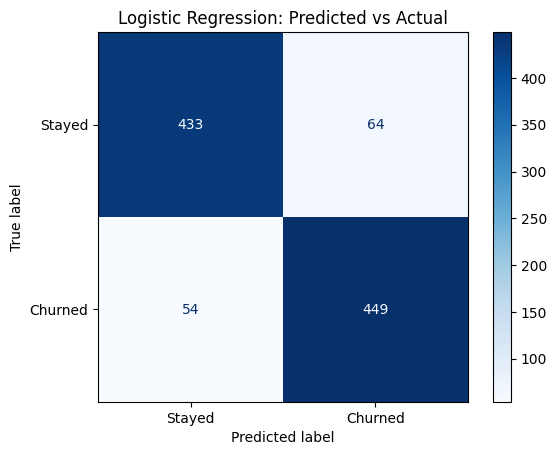

In [19]:
# Show how many test subscribers were predicted correctly and incorrectly
ConfusionMatrixDisplay.from_estimator(
    log_reg_model, X_test, y_test, display_labels=["Stayed", "Churned"], cmap="Blues"
)
plt.title("Logistic Regression: Predicted vs Actual")
plt.show()

**Observations:**
- Logistic Regression got **88.2%** of test subscribers right, compared to **50.3%** for always guessing "churned," 
- **Precision (87.5%)** and **recall (89.3%)** are close, so the model is about equally good at avoiding false alarms and catching churners
- Out of 503 subscribers in the test set who churned, the model caught **449** and missed **54**. It also flagged **64** subscribers who actually stayed
- **ROC-AUC is 0.961**, so the model is very good at ranking subscribers by risk. This matters for retention teams, who could contact the highest-risk subscribers first